In [4]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
import warnings
warnings.filterwarnings("ignore")

In [5]:
GROUP = "C1"
DTYPE="G_H"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C1_10,27,"[DATA/TRAINING/C1/C1_10/IMG_6497.HEIC, DATA/TR..."
1,C1_11,26,"[DATA/TRAINING/C1/C1_11/IMG_6665.HEIC, DATA/TR..."
2,C1_12,27,"[DATA/TRAINING/C1/C1_12/IMG_6797.HEIC, DATA/TR..."
3,C1_13,27,"[DATA/TRAINING/C1/C1_13/IMG_6929.HEIC, DATA/TR..."
4,C1_14,26,"[DATA/TRAINING/C1/C1_14/IMG_7188.HEIC, DATA/TR..."
5,C1_15,28,"[DATA/TRAINING/C1/C1_15/IMG_7316.HEIC, DATA/TR..."
6,C1_16,27,"[DATA/TRAINING/C1/C1_16/IMG_7446.HEIC, DATA/TR..."


In [6]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [7]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [8]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16 %')

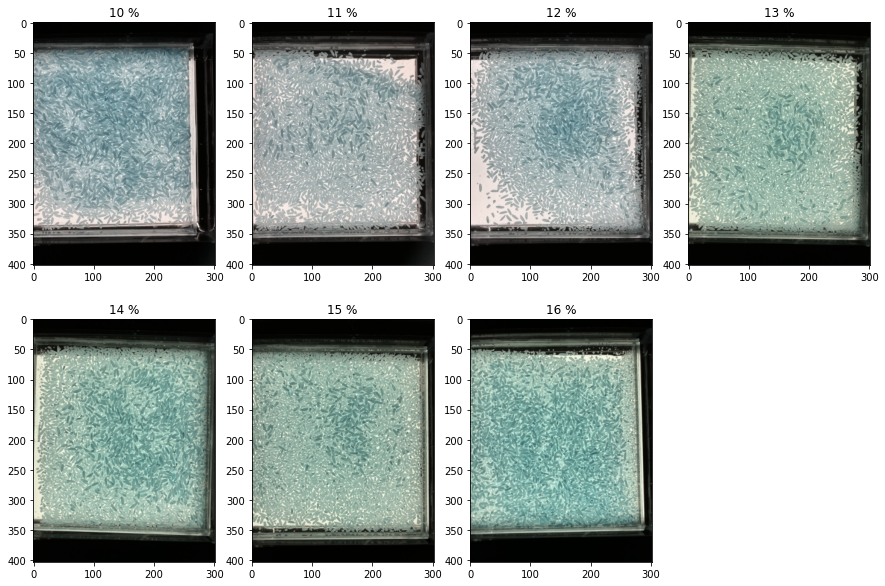

In [9]:
fig=plt.figure(figsize=(15, 10)) 
ax1 = fig.add_subplot(2,4,1)
image = read_imgHEIC(data_path[0][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10 %")
ax2 = fig.add_subplot(2,4,2)
image = read_imgHEIC(data_path[1][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11 %")
ax3 = fig.add_subplot(2,4,3)
image = read_imgHEIC(data_path[2][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12 %")
ax4 = fig.add_subplot(2,4,4)
image = read_imgHEIC(data_path[3][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13 %")
ax5 = fig.add_subplot(2,4,5)
image = read_imgHEIC(data_path[4][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14 %")
ax6 = fig.add_subplot(2,4,6)
image = read_imgHEIC(data_path[5][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15 %")
ax7 = fig.add_subplot(2,4,7)
image = read_imgHEIC(data_path[6][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16 %")

In [10]:
def fd_gray(gray, bins, mask=None):
    # compute the gray color histogram
    hist  = cv2.calcHist([gray], [0], None, [bins], [0, 256])
    # normalize the histogram
    cv2.normalize(hist, hist)
    # return the histogram
    return hist, hist.flatten()

In [11]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
bins=44; #width=2024; height=3032; 
scale=25
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        #Compute 1D gray histogram
        [grayHist, grayNormHist]=fd_gray(gray, bins)
        arr_img_hist.append(grayNormHist)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["bins"] = bins
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [12]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(bins)+'bins.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,41,42,43,scale,bins,height,width,channels,IMAGENAME,HUMIDITY
0,0.522476,0.085060,0.127144,0.129009,0.094874,0.083602,0.088813,0.086838,0.048200,0.032307,...,0.034350,0.023558,0.004356,25,44,1008,756,3,IMG_6497.HEIC,10
1,0.527794,0.090620,0.119557,0.129244,0.097124,0.083273,0.097810,0.089427,0.076731,0.033313,...,0.023376,0.017234,0.002884,25,44,1008,756,3,IMG_6498.HEIC,10
2,0.554033,0.115277,0.133729,0.133723,0.103002,0.086731,0.106918,0.102140,0.050468,0.028491,...,0.033391,0.021703,0.006556,25,44,1008,756,3,IMG_6499.HEIC,10
3,0.549248,0.117579,0.132914,0.134211,0.097036,0.079588,0.102373,0.104361,0.065216,0.032895,...,0.040393,0.022019,0.003971,25,44,1008,756,3,IMG_6500.HEIC,10
4,0.545593,0.113533,0.135322,0.139035,0.100234,0.088067,0.110554,0.099843,0.050759,0.029270,...,0.037461,0.022070,0.003426,25,44,1008,756,3,IMG_6501.HEIC,10
5,0.547809,0.091030,0.135362,0.104617,0.087465,0.067857,0.065018,0.054386,0.045416,0.043101,...,0.030234,0.018993,0.003392,25,44,1008,756,3,IMG_6502.HEIC,10
6,0.649674,0.112687,0.118296,0.095107,0.058504,0.045171,0.058164,0.053962,0.041672,0.031197,...,0.033188,0.019815,0.003732,25,44,1008,756,3,IMG_6503.HEIC,10
7,0.630457,0.115265,0.111257,0.112463,0.070684,0.055227,0.056260,0.038627,0.031489,0.027246,...,0.041624,0.016876,0.002067,25,44,1008,756,3,IMG_6504.HEIC,10
8,0.631652,0.119367,0.113736,0.112570,0.073319,0.055961,0.061928,0.046979,0.034816,0.030440,...,0.033667,0.022624,0.004011,25,44,1008,756,3,IMG_6505.HEIC,10
9,0.633137,0.118169,0.112174,0.113651,0.073330,0.056823,0.061605,0.045845,0.034509,0.030638,...,0.032773,0.020825,0.003018,25,44,1008,756,3,IMG_6506.HEIC,10


# Classification

In [13]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-7]
#X

In [14]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [15]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [16]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [17]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [19]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.789474,0.809524,0.809524,0.809524,G_H,C1,RF_C,25,44,1008,756,3
1,2,0.947368,0.964286,0.952381,0.958296,G_H,C1,RF_C,25,44,1008,756,3
2,3,1.000000,1.000000,1.000000,1.000000,G_H,C1,RF_C,25,44,1008,756,3
3,4,0.842105,0.833333,0.833333,0.833333,G_H,C1,RF_C,25,44,1008,756,3
4,5,0.947368,0.964286,0.952381,0.958296,G_H,C1,RF_C,25,44,1008,756,3
5,6,0.842105,0.869048,0.833333,0.850816,G_H,C1,RF_C,25,44,1008,756,3
6,7,0.789474,0.859524,0.785714,0.820963,G_H,C1,RF_C,25,44,1008,756,3
7,8,1.000000,1.000000,1.000000,1.000000,G_H,C1,RF_C,25,44,1008,756,3
8,9,0.777778,0.821429,0.761905,0.790548,G_H,C1,RF_C,25,44,1008,756,3
9,10,0.888889,0.942857,0.857143,0.897959,G_H,C1,RF_C,25,44,1008,756,3


In [20]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,G_H,C1,RF_C,0.882456,0.878571,0.891974,0.906429


### MLP Classifier

In [21]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [22]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [23]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.842105,0.895238,0.809524,0.850226,G_H,C1,MLP_C,25,44,1008,756,3
1,2,0.894737,0.904762,0.904762,0.904762,G_H,C1,MLP_C,25,44,1008,756,3
2,3,0.947368,0.964286,0.952381,0.958296,G_H,C1,MLP_C,25,44,1008,756,3
3,4,0.947368,0.952381,0.952381,0.952381,G_H,C1,MLP_C,25,44,1008,756,3
4,5,0.789474,0.821429,0.785714,0.803175,G_H,C1,MLP_C,25,44,1008,756,3
5,6,0.894737,0.892857,0.880952,0.886865,G_H,C1,MLP_C,25,44,1008,756,3
6,7,0.736842,0.750000,0.738095,0.744000,G_H,C1,MLP_C,25,44,1008,756,3
7,8,0.736842,0.773810,0.738095,0.755531,G_H,C1,MLP_C,25,44,1008,756,3
8,9,1.000000,1.000000,1.000000,1.000000,G_H,C1,MLP_C,25,44,1008,756,3
9,10,0.944444,0.964286,0.952381,0.958296,G_H,C1,MLP_C,25,44,1008,756,3


In [24]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,G_H,C1,MLP_C,0.873392,0.871429,0.881353,0.891905


### XGBoost Classifier

In [25]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [26]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.842105,0.857143,0.833333,0.845070,G_H,C1,XGB_C,25,44,1008,756,3
1,2,0.736842,0.833333,0.738095,0.782828,G_H,C1,XGB_C,25,44,1008,756,3
2,3,1.000000,1.000000,1.000000,1.000000,G_H,C1,XGB_C,25,44,1008,756,3
3,4,0.736842,0.702381,0.738095,0.719795,G_H,C1,XGB_C,25,44,1008,756,3
4,5,0.789474,0.892857,0.761905,0.822199,G_H,C1,XGB_C,25,44,1008,756,3
5,6,0.789474,0.845238,0.761905,0.801411,G_H,C1,XGB_C,25,44,1008,756,3
6,7,0.894737,0.916667,0.904762,0.910675,G_H,C1,XGB_C,25,44,1008,756,3
7,8,0.736842,0.797619,0.738095,0.766704,G_H,C1,XGB_C,25,44,1008,756,3
8,9,0.666667,0.728571,0.666667,0.696246,G_H,C1,XGB_C,25,44,1008,756,3
9,10,0.888889,0.916667,0.880952,0.898455,G_H,C1,XGB_C,25,44,1008,756,3


In [27]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,G_H,C1,XGB_C,0.808187,0.802381,0.824338,0.849048


# External validation

In [28]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C1_10,5,"[DATA/TEST/C1/C1_10/IMG_6492.HEIC, DATA/TEST/C..."
1,C1_11,5,"[DATA/TEST/C1/C1_11/IMG_6655.HEIC, DATA/TEST/C..."
2,C1_12,5,"[DATA/TEST/C1/C1_12/IMG_6788.HEIC, DATA/TEST/C..."
3,C1_13,5,"[DATA/TEST/C1/C1_13/IMG_6917.HEIC, DATA/TEST/C..."
4,C1_14,5,"[DATA/TEST/C1/C1_14/IMG_7178.HEIC, DATA/TEST/C..."
5,C1_15,5,"[DATA/TEST/C1/C1_15/IMG_7304.HEIC, DATA/TEST/C..."
6,C1_16,5,"[DATA/TEST/C1/C1_16/IMG_7436.HEIC, DATA/TEST/C..."


In [29]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [30]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        #Compute 1D gray histogram
        [grayHist, grayNormHist]=fd_gray(gray, bins)
        arr_img_hist.append(grayNormHist)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["bins"] = bins
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [31]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(bins)+'bins.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,41,42,43,scale,bins,height,width,channels,IMAGENAME,HUMIDITY
0,0.534480,0.100192,0.143015,0.131739,0.098078,0.080923,0.111017,0.104853,0.078054,0.030465,...,0.033500,0.019381,0.010899,25,44,1008,756,3,IMG_6492.HEIC,10
1,0.543004,0.107101,0.130842,0.138803,0.095245,0.080471,0.104838,0.097502,0.053108,0.031399,...,0.027770,0.016752,0.006571,25,44,1008,756,3,IMG_6493.HEIC,10
2,0.577708,0.113303,0.150318,0.121978,0.093173,0.079698,0.098546,0.113054,0.070608,0.035945,...,0.044461,0.022661,0.005743,25,44,1008,756,3,IMG_6494.HEIC,10
3,0.561279,0.108087,0.146310,0.147392,0.113464,0.096027,0.110644,0.089832,0.035035,0.024726,...,0.032347,0.019999,0.009240,25,44,1008,756,3,IMG_6495.HEIC,10
4,0.542225,0.105092,0.117739,0.145939,0.108370,0.083595,0.092970,0.081317,0.045266,0.023368,...,0.033959,0.023806,0.005036,25,44,1008,756,3,IMG_6496.HEIC,10
0,0.589939,0.051837,0.079338,0.087956,0.051437,0.041618,0.063892,0.052466,0.047778,0.046933,...,0.089424,0.041201,0.005032,25,44,1008,756,3,IMG_6655.HEIC,11
1,0.575122,0.049926,0.076625,0.094876,0.056575,0.038990,0.051387,0.053175,0.040029,0.042984,...,0.087017,0.049587,0.005849,25,44,1008,756,3,IMG_6657.HEIC,11
2,0.597728,0.065641,0.120507,0.095061,0.062900,0.044707,0.066349,0.066783,0.049161,0.044227,...,0.078695,0.035473,0.004665,25,44,1008,756,3,IMG_6659.HEIC,11
3,0.602281,0.059354,0.094260,0.090546,0.087405,0.060781,0.048920,0.043943,0.043650,0.039304,...,0.069338,0.025840,0.003036,25,44,1008,756,3,IMG_6662.HEIC,11
4,0.625619,0.054277,0.066238,0.094942,0.086695,0.054149,0.061300,0.051910,0.051096,0.048679,...,0.070667,0.042800,0.008467,25,44,1008,756,3,IMG_6663.HEIC,11


In [32]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [33]:
X_test = dtFeaturesTest.values[:, :-7]
#X_test

In [34]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [35]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [36]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.83      1.00      0.91         5
     Class 1       1.00      0.80      0.89         5
     Class 2       0.80      0.80      0.80         5
     Class 3       0.36      0.80      0.50         5
     Class 4       0.83      1.00      0.91         5
     Class 5       0.50      0.20      0.29         5
     Class 6       1.00      0.20      0.33         5

    accuracy                           0.69        35
   macro avg       0.76      0.69      0.66        35
weighted avg       0.76      0.69      0.66        35



## MLP

In [37]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [38]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00         5
     Class 1       1.00      1.00      1.00         5
     Class 2       1.00      0.60      0.75         5
     Class 3       0.36      0.80      0.50         5
     Class 4       0.71      1.00      0.83         5
     Class 5       0.50      0.20      0.29         5
     Class 6       1.00      0.40      0.57         5

    accuracy                           0.71        35
   macro avg       0.80      0.71      0.71        35
weighted avg       0.80      0.71      0.71        35



## XGBC

In [39]:
y_pred = modelXGBC.predict(X_test_scale) 

In [40]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00         5
     Class 1       0.67      0.80      0.73         5
     Class 2       1.00      0.80      0.89         5
     Class 3       0.45      1.00      0.62         5
     Class 4       0.80      0.80      0.80         5
     Class 5       0.50      0.20      0.29         5
     Class 6       0.50      0.20      0.29         5

    accuracy                           0.69        35
   macro avg       0.70      0.69      0.66        35
weighted avg       0.70      0.69      0.66        35

